# Бинарные деревья поиска

После пары вы сможете:

- объяснить свойство бинарного дерева поиска и нарисовать дерево по последовательности чисел;
- проследить по шагам вставку, поиск, successor, минимум, максимум и удаление;
- сказать, почему «плохое» дерево вырождается в цепочку и сколько это стоит;
- объяснить идею AVL: баланс высот и повороты;
- выбрать структуру под задачу: обычное BST, AVL или анонс других деревьев.

## План пары (около 90 минут)

1. Структура и свойство BST.
2. Вставка.
3. Поиск, successor, минимум и максимум.
4. Удаление.
5. AVL: баланс и повороты.
6. Анонс других деревьев и сводка «что выбрать».


## Перед началом

Короткая лекция [CS50](https://www.youtube.com/watch?v=YzT8zDPihmc&t=7s)

 Запустите ячейку ниже один раз. После этого под операциями появится поле: впишите числа через пробел или запятую (и ключ, если нужен) и нажмите кнопку. Ниже появятся шаги.

**Слова, которые встретятся дальше:**

- **Узел** хранит ключ и ссылки на левого и правого ребёнка. **Корень** — верхний узел, **лист** — узел без детей.
- **Высота** поддерева — длина самого длинного пути вниз от его корня (у пустого дерева считаем −1, у листа — 0).
- **Что верно после каждого шага** — утверждение, которое алгоритм не нарушает. В учебниках его называют инвариантом.
- **Сбалансированное дерево** — высоты левого и правого поддеревьев у каждого узла близки; иначе дерево может стать «палкой».


In [ ]:
def read_numbers(text):
    """Превращает строку «5, 2 9» в список [5, 2, 9]."""
    return [int(part) for part in text.replace(",", " ").split()]


def _run_with_widgets(fields, button_label, runner):
    try:
        import ipywidgets as widgets
        from IPython.display import display
    except ImportError:
        values = []
        for name, example in fields:
            values.append(input(f"{name} (Enter — пример {example}): ").strip() or example)
        runner(*values)
        return

    widgets_list = [widgets.Text(value=example, description=f"{name}:") for name, example in fields]
    button = widgets.Button(description=button_label)
    output = widgets.Output()

    def on_click(_):
        output.clear_output()
        with output:
            runner(*(w.value for w in widgets_list))

    button.on_click(on_click)
    display(widgets.HBox(widgets_list + [button]), output)


def try_sequence(action, example="8 3 10 1 6 14 4 7 13"):
    """Поле: последовательность ключей для построения дерева и операции."""

    def run(text):
        text = text.strip() or example
        try:
            keys = read_numbers(text)
        except ValueError:
            print("Нужны целые числа через пробел или запятую, например: 8 3 10 1 6")
            return
        action(keys)

    _run_with_widgets([("Числа", example)], "Показать", run)


def try_sequence_and_key(action, example_seq="8 3 10 1 6 14 4 7 13", example_key="6"):
    """Поля: последовательность для дерева и ключ операции."""

    def run(seq_text, key_text):
        seq_text = seq_text.strip() or example_seq
        key_text = key_text.strip() or example_key
        try:
            keys = read_numbers(seq_text)
            key = int(key_text.replace(",", " ").split()[0])
        except (ValueError, IndexError):
            print("Нужны целые числа для дерева и один целый ключ операции")
            return
        action(keys, key)

    _run_with_widgets(
        [("Числа", example_seq), ("Ключ", example_key)],
        "Выполнить",
        run,
    )

## Структура бинарного дерева поиска

**Идея.** Это упорядоченный словарь в виде дерева. У каждого узла не больше двух детей. Идём от корня: меньшие ключи — налево, большие — направо. Так поиск похож на бинарный поиск в отсортированном списке, но дерево ещё умеет вставлять и удалять без сдвига всего массива.

**Что верно в каждом узле.** Для любого узла со значением $k$: все ключи в левом поддереве строго меньше $k$, все ключи в правом — строго больше $k$. На этой паре дубликаты не храним: повторный ключ при вставке отвергаем.

**Автор и год.** Бинарные деревья поиска как структура данных оформились в начале 1960-х (работы П. Ф. Уиндли, А. Д. Бута и др., 1960). Дальше на их идее выросли сбалансированные варианты.

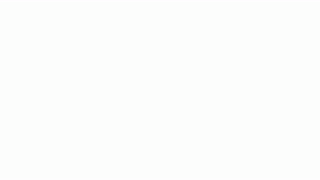


In [ ]:
from __future__ import annotations

from collections import deque
from dataclasses import dataclass


@dataclass
class Node:
    key: int
    left: Node | None = None
    right: Node | None = None


def print_tree(root: Node | None) -> None:
    """Печатает дерево по уровням: удобно сверять шаги глазами."""
    if root is None:
        print("(пустое дерево)")
        return
    queue: deque[Node | None] = deque([root])
    levels: list[list[str]] = []
    while queue:
        size = len(queue)
        level: list[str] = []
        next_row_has_node = False
        for _ in range(size):
            node = queue.popleft()
            if node is None:
                level.append(".")
                queue.append(None)
                queue.append(None)
            else:
                level.append(str(node.key))
                queue.append(node.left)
                queue.append(node.right)
                if node.left is not None or node.right is not None:
                    next_row_has_node = True
        levels.append(level)
        if not next_row_has_node:
            break
    for level in levels:
        print(" ".join(level))


def build_bst(keys: list[int]) -> Node | None:
    root = None
    for key in keys:
        root = insert(root, key, verbose=False)
    return root

**Оценка сложности .** Высота дерева $h$ задаёт длину типичного пути. В «удачном» дереве $h \approx \log_2 n$, в вырожденном (все ключи по возрастанию) $h = n-1$. Память — $O(n)$ узлов.

**Когда выбирать.** Нужен и поиск, и частые вставки/удаления упорядоченных ключей, и важно уметь ходить «к соседу» (min, max, successor).

**Когда не стоит.** Только поиск по ключу без порядка — часто достаточно хеш-таблицы. Нужна гарантия $\log n$ — обычное BST без балансировки не подходит.

**Пограничные случаи**

- Пустое дерево — корня нет.
- Один узел — и корень, и лист.
- Отсортированный ввод — дерево становится цепочкой (см. анимацию ниже).

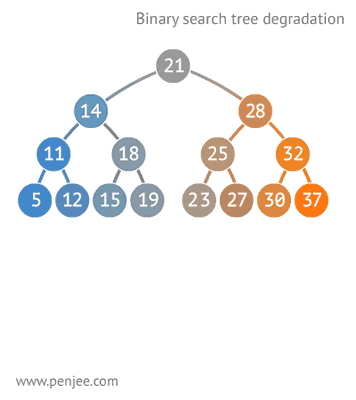



## Вставка

**Идея.** Ищем место для нового ключа так же, как при поиске. Когда упёрлись в пустую ссылку — вешаем туда новый лист. Первая вставка создаёт корень.

**Что верно после каждого шага.** Пока идём вниз, все уже существующие узлы сохраняют свойство BST. Новый узел становится листом, поэтому соседей «перешивать» не нужно.

**Автор и год.** Та же линия работ начала 1960-х; вставка — базовая операция BST.

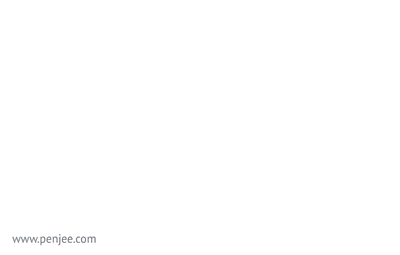


In [ ]:
def insert(root: Node | None, key: int, verbose: bool = True) -> Node:
    # Что верно на каждом шаге: идём по пути поиска; слева от пути — меньшие, справа — большие.
    def say(msg: str) -> None:
        if verbose:
            print(msg)

    if root is None:
        say(f"создаём узел {key}")
        return Node(key)
    current = root
    while True:
        if key == current.key:
            say(f"ключ {key} уже есть — не вставляем")
            return root
        if key < current.key:
            say(f"{key} < {current.key} — налево")
            if current.left is None:
                current.left = Node(key)
                say(f"вешаем {key} слева от {current.key}")
                return root
            current = current.left
        else:
            say(f"{key} > {current.key} — направо")
            if current.right is None:
                current.right = Node(key)
                say(f"вешаем {key} справа от {current.key}")
                return root
            current = current.right


print("пример: вставляем по одному")
demo = None
for k in [8, 3, 10, 1, 6, 14, 4, 7, 13]:
    print(f"--- insert({k}) ---")
    demo = insert(demo, k)
print("дерево по уровням:")
print_tree(demo)

пример: вставляем по одному
--- insert(8) ---
создаём узел 8
--- insert(3) ---
3 < 8 — налево
вешаем 3 слева от 8
--- insert(10) ---
10 > 8 — направо
вешаем 10 справа от 8
--- insert(1) ---
1 < 8 — налево
1 < 3 — налево
вешаем 1 слева от 3
--- insert(6) ---
6 < 8 — налево
6 > 3 — направо
вешаем 6 справа от 3
--- insert(14) ---
14 > 8 — направо
14 > 10 — направо
вешаем 14 справа от 10
--- insert(4) ---
4 < 8 — налево
4 > 3 — направо
4 < 6 — налево
вешаем 4 слева от 6
--- insert(7) ---
7 < 8 — налево
7 > 3 — направо
7 > 6 — направо
вешаем 7 справа от 6
--- insert(13) ---
13 > 8 — направо
13 > 10 — направо
13 < 14 — налево
вешаем 13 слева от 14
дерево по уровням:
8
3 10
1 6 . 14
. . 4 7 . . 13 .


**Оценка сложности**

- Время: $O(h)$, где $h$ — высота. В среднем часто около $O(\log n)$, в худшем $O(n)$.
- Память: $O(1)$ дополнительно к новому узлу (итеративная вставка).
- На месте относительно списка узлов: меняем только ссылки.

**Когда выбирать.** Базовый способ наполнить BST.

**Когда не стоит.** Если ключи приходят уже отсортированными — без балансировки получите цепочку.

**Пограничные случаи**

- Первая вставка — появляется корень.
- Дубликат — не вставляем.
- Вставка в лист на 3–4-м уровне — путь из нескольких сравнений.


## Удаление

**Идея.** Три случая:

1. **Лист** — просто отцепляем.
2. **Один ребёнок** — поднимаем ребёнка на место узла.
3. **Два ребёнка** — находим successor (минимум в правом поддереве), копируем его ключ в удаляемый узел и удаляем successor (у него уже не будет двух детей).

**Что верно после удаления.** Ссылки переставлены так, что свойство BST снова выполняется для всего дерева.
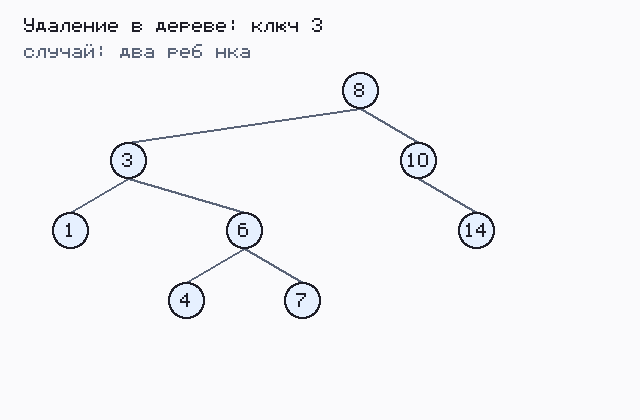


In [ ]:
#%%
def find_min(root: Node | None) -> Node | None:
    if root is None:
        print("дерево пустое")
        return None
    current = root
    while current.left is not None:
        print(f"у {current.key} есть левый ребёнок {current.left.key} — идём за минимумом")
        current = current.left
    print(f"минимум: {current.key}")
    return current


def find_max(root: Node | None) -> Node | None:
    if root is None:
        print("дерево пустое")
        return None
    current = root
    while current.right is not None:
        print(f"у {current.key} есть правый ребёнок {current.right.key} — идём за максимумом")
        current = current.right
    print(f"максимум: {current.key}")
    return current
def delete_node(root: Node | None, key: int) -> Node | None:
    # Что верно: после возврата из рекурсии поддерево снова удовлетворяет свойству BST.
    if root is None:
        print(f"ключа {key} нет")
        return None
    if key < root.key:
        print(f"{key} < {root.key} — удаляем слева")
        root.left = delete_node(root.left, key)
        return root
    if key > root.key:
        print(f"{key} > {root.key} — удаляем справа")
        root.right = delete_node(root.right, key)
        return root

    print(f"удаляем узел {key}")
    if root.left is None and root.right is None:
        print("  случай 1: лист")
        return None
    if root.left is None:
        print("  случай 2: только правый ребёнок")
        return root.right
    if root.right is None:
        print("  случай 2: только левый ребёнок")
        return root.left

    print("  случай 3: два ребёнка — берём successor")
    succ = find_min(root.right)
    assert succ is not None
    print(f"  копируем ключ {succ.key} в узел {root.key}")
    root.key = succ.key
    root.right = delete_node(root.right, succ.key)
    return root


print("удаление листа 1:")
t = build_bst([8, 3, 10, 1, 6])
print_tree(delete_node(t, 1))
print("удаление корня 8 (два ребёнка):")
t = build_bst([8, 3, 10, 1, 6])
print_tree(delete_node(t, 8))

удаление листа 1:
1 < 8 — удаляем слева
1 < 3 — удаляем слева
удаляем узел 1
  случай 1: лист
8
3 10
. 6 . .
удаление корня 8 (два ребёнка):
удаляем узел 8
  случай 3: два ребёнка — берём successor
минимум: 10
  копируем ключ 10 в узел 8
удаляем узел 10
  случай 1: лист
10
3 .
1 6 . .


**Оценка сложности.** $O(h)$ сравнений и перестановок ссылок. Память стека рекурсии $O(h)$ (можно сделать итеративно).

**Когда выбирать.** Нужно поддерживать множество ключей с удалением.

**Когда не стоит.** Если удаления редки, а гарантированная высота критична — смотрите AVL и другие сбалансированные деревья.

**Пограничные случаи**

- Удаление из конца (лист) и «из начала» (корень).
- Ключ отсутствует — дерево не меняется.
- Successor при двух детях всегда существует в правом поддереве.


## Поиск, successor, минимум и максимум

**Идея .** Сравниваем ключ с текущим узлом: меньше — налево, больше — направо, равно — нашли. Если путь оборвался — ключа нет.

**Минимум** — всё время налево до конца. **Максимум** — всё время направо.

**Successor** (следующий по порядку ключ): если есть правое поддерево — это его минимум; иначе поднимаемся к предку, от которого впервые ушли налево (в учебной реализации часто ищем от корня заново среди больших ключей).

**Что верно на каждом шаге поиска.** Текущий узел — единственный кандидат на пути; всё левее пути уже отброшено как слишком маленькое или слишком большое.

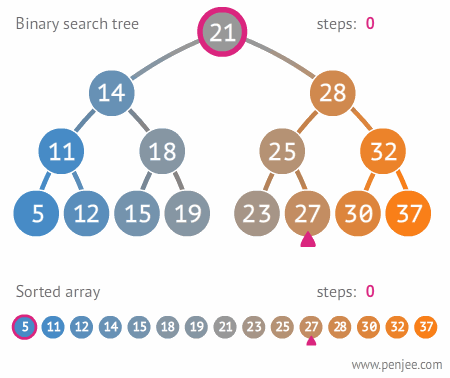


In [ ]:
def search(root: Node | None, key: int) -> Node | None:
    # Что верно: если ключ есть в дереве, он лежит в текущем поддереве.
    current = root
    while current is not None:
        if key == current.key:
            print(f"нашли {key}")
            return current
        if key < current.key:
            print(f"{key} < {current.key} — налево")
            current = current.left
        else:
            print(f"{key} > {current.key} — направо")
            current = current.right
    print(f"ключа {key} нет")
    return None


def find_min(root: Node | None) -> Node | None:
    if root is None:
        print("дерево пустое")
        return None
    current = root
    while current.left is not None:
        print(f"у {current.key} есть левый ребёнок {current.left.key} — идём за минимумом")
        current = current.left
    print(f"минимум: {current.key}")
    return current


def find_max(root: Node | None) -> Node | None:
    if root is None:
        print("дерево пустое")
        return None
    current = root
    while current.right is not None:
        print(f"у {current.key} есть правый ребёнок {current.right.key} — идём за максимумом")
        current = current.right
    print(f"максимум: {current.key}")
    return current


def successor(root: Node | None, key: int) -> Node | None:
    # Учебный вариант: один проход от корня, помним последнего предка, большего ключа.
    current = root
    succ: Node | None = None
    while current is not None:
        if key < current.key:
            print(f"{key} < {current.key} — возможный successor {current.key}, налево")
            succ = current
            current = current.left
        elif key > current.key:
            print(f"{key} > {current.key} — направо")
            current = current.right
        else:
            if current.right is not None:
                print(f"у {key} есть правое поддерево — successor = минимум справа")
                return find_min(current.right)
            break
    if succ is None:
        print(f"у {key} нет successor")
    else:
        print(f"successor({key}) = {succ.key}")
    return succ


demo = build_bst([8, 3, 10, 1, 6, 14, 4, 7, 13])
print("дерево:")
print_tree(demo)
print("--- search 6 ---")
search(demo, 6)
print("--- search 2 ---")
search(demo, 2)
print("--- min / max ---")
find_min(demo)
find_max(demo)
print("--- successor 7 ---")
successor(demo, 7)
print("--- successor 14 ---")
successor(demo, 14)

дерево:
8
3 10
1 6 . 14
. . 4 7 . . 13 .
--- search 6 ---
6 < 8 — налево
6 > 3 — направо
нашли 6
--- search 2 ---
2 < 8 — налево
2 < 3 — налево
2 > 1 — направо
ключа 2 нет
--- min / max ---
у 8 есть левый ребёнок 3 — идём за минимумом
у 3 есть левый ребёнок 1 — идём за минимумом
минимум: 1
у 8 есть правый ребёнок 10 — идём за максимумом
у 10 есть правый ребёнок 14 — идём за максимумом
максимум: 14
--- successor 7 ---
7 < 8 — возможный successor 8, налево
7 > 3 — направо
7 > 6 — направо
successor(7) = 8
--- successor 14 ---
14 > 8 — направо
14 > 10 — направо
у 14 нет successor


**Оценка сложности.** Каждая операция — $O(h)$. В сбалансированном дереве это $O(\log n)$, в вырожденном — $O(n)$.

**Когда выбирать.** Нужен порядок: «следующий», диапазоны, минимум/максимум за время пути, а не полный просмотр списка.

**Когда не стоит.** Хеш-таблица даёт средний $O(1)$ на «есть/нет», но не даёт successor «бесплатно».

**Пограничные случаи**

- Ключ найден / не найден.
- Successor у максимума отсутствует.
- Min/max в пустом дереве — отдельный ответ.


## AVL-деревья

**Идея.** Обычное BST может вытянуться. AVL (Адельсон-Вельский и Ландис, **1962**) после каждой вставки (и удаления) восстанавливает баланс: у каждого узла высоты левого и правого поддеревьев отличаются не больше чем на 1.

**Что верно после балансировки.** Свойство BST сохраняется (повороты не ломают порядок), а разница высот снова не больше единицы. Высота всего дерева тогда $O(\log n)$, и поиск/вставка/удаление — $O(\log n)$ в худшем случае.

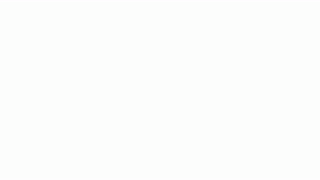


In [ ]:
@dataclass
class AvlNode:
    key: int
    left: AvlNode | None = None
    right: AvlNode | None = None
    height: int = 0


def height(node: AvlNode | None) -> int:
    return -1 if node is None else node.height


def update(node: AvlNode) -> None:
    node.height = 1 + max(height(node.left), height(node.right))


def balance_factor(node: AvlNode) -> int:
    return height(node.left) - height(node.right)


def rotate_right(y: AvlNode) -> AvlNode:
    # Что верно: порядок ключей сохраняется, y становится правым ребёнком x.
    print(f"правый поворот вокруг {y.key}")
    x = y.left
    assert x is not None
    y.left = x.right
    x.right = y
    update(y)
    update(x)
    return x


def rotate_left(x: AvlNode) -> AvlNode:
    print(f"левый поворот вокруг {x.key}")
    y = x.right
    assert y is not None
    x.right = y.left
    y.left = x
    update(x)
    update(y)
    return y


def avl_insert(root: AvlNode | None, key: int) -> AvlNode:
    if root is None:
        print(f"создаём AVL-узел {key}")
        return AvlNode(key)
    if key == root.key:
        print(f"ключ {key} уже есть")
        return root
    if key < root.key:
        print(f"{key} < {root.key} — налево")
        root.left = avl_insert(root.left, key)
    else:
        print(f"{key} > {root.key} — направо")
        root.right = avl_insert(root.right, key)
    update(root)
    bf = balance_factor(root)
    print(f"узел {root.key}: balance = {bf}")
    # LL
    if bf > 1 and key < root.left.key:  # type: ignore[union-attr]
        return rotate_right(root)
    # RR
    if bf < -1 and key > root.right.key:  # type: ignore[union-attr]
        return rotate_left(root)
    # LR
    if bf > 1 and key > root.left.key:  # type: ignore[union-attr]
        print("случай LR")
        root.left = rotate_left(root.left)  # type: ignore[arg-type]
        return rotate_right(root)
    # RL
    if bf < -1 and key < root.right.key:  # type: ignore[union-attr]
        print("случай RL")
        root.right = rotate_right(root.right)  # type: ignore[arg-type]
        return rotate_left(root)
    return root


def print_avl(root: AvlNode | None) -> None:
    # Переиспользуем уровневую печать через простые Node.
    def to_plain(node: AvlNode | None) -> Node | None:
        if node is None:
            return None
        return Node(node.key, to_plain(node.left), to_plain(node.right))

    print_tree(to_plain(root))


print("AVL: вставка 1 2 3 (нужен левый поворот)")
avl = None
for k in [1, 2, 3]:
    print(f"--- avl_insert({k}) ---")
    avl = avl_insert(avl, k)
    print_avl(avl)

AVL: вставка 1 2 3 (нужен левый поворот)
--- avl_insert(1) ---
создаём AVL-узел 1
1
--- avl_insert(2) ---
2 > 1 — направо
создаём AVL-узел 2
узел 1: balance = -1
1
. 2
--- avl_insert(3) ---
3 > 1 — направо
3 > 2 — направо
создаём AVL-узел 3
узел 2: balance = -1
узел 1: balance = -2
левый поворот вокруг 1
2
1 3


**Оценка сложности.** Поиск, вставка (с поворотами) — $O(\log n)$ в худшем случае. Память $O(n)$, в узле хранят высоту или баланс.

**Когда выбирать.** Нужна гарантированная логарифмическая высота на учебных и многих прикладных задачах.

**Когда не стоит.** Если достаточно «в среднем хорошо» и проще код обычного BST; в проде часто берут другие сбалансированные деревья (см. анонс).

**Пограничные случаи**

- Вставка, которая не нарушает баланс — поворотов нет.
- Цепочка 1–2–3 — один левый поворот.
- Случаи LR/RL — двойной поворот.


## Другие деревья — Поговорим в следующей лекции

Коротко, без разбора алгоритмов на этой паре:

| Структура | Зачем упоминаем |
| --- | --- |
| Красно-чёрное дерево | Другой способ держать высоту $O(\log n)$; часто в библиотеках (`std::map`, TreeMap) |
| B-дерево / B+ | Много ключей в одном узле — дружит с диском и БД, индексами |
| Treap / декартово дерево | Случайные приоритеты + BST по ключу |
| Splay | «Всплытие» часто используемых узлов |

Подробности — в теме `7_other_search_tree`.


### Красно-чёрное дерево

Другой способ держать высоту $O(\log n)$: узлы красят в красный и чёрный, после вставки чинят дерево **перекраской** и **поворотами**. В библиотеках часто именно оно (`std::map`, TreeMap).


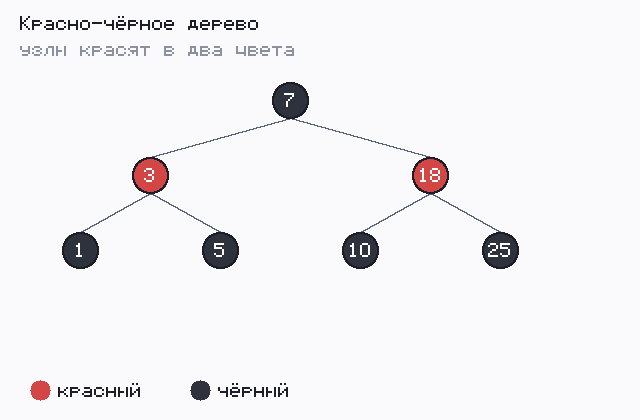


### Б-дерево (B-tree)

В узле много ключей — меньше высота и меньше обращений к диску. Так устроены индексы в базах данных (часто в варианте B+).
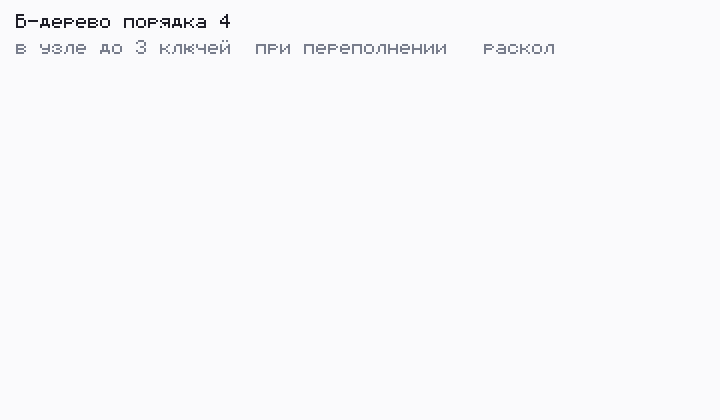

## Что выбрать

| Структура | Поиск / вставка / удаление | Гарантия высоты | Когда уместно |
| --- | --- | --- | --- |
| Обычное BST | $O(h)$ | нет, хуже $O(n)$ | почти всегда только для ознакомления |
| AVL | $O(\log n)$ | да | нужна гарантия поиск $O(\log n)$ |
| Отсортированный список | поиск $O(\log n)$, вставка $O(n)$ | — | если сам список неизменный и данных мало |
| B-дерево и др. | $O(\log n)$ | да (по-своему) | если данных очень много и нужно сократить грубину |

**Коротко:** начните с свойства BST и трёх случаев удаления. Если вход может быть отсортированным — думайте о балансировке (AVL или анонс других деревьев).


Семинар: https://app.holst.so/share/b/cbaff349-e652-4bb5-96de-56ba079e8374